# 03 PyTorchによるCPU・GPU計算

同じ行列積をCPUと利用可能なGPUで測り、同期とデータ転送の影響を比べます。

必要なライブラリ：PyTorch、NumPy、Matplotlib

[Google Colabで開く](https://colab.research.google.com/github/m-riho/information-science-interactive-lab/blob/main/public/notebooks/session07/03_pytorch_gpu.ipynb)

Colabリンクは、このファイルを既存の公開リポジトリへ反映した後に利用できます。

Python 3.12以降を想定し、作者の実行検証はPython 3.13.5で行います。
依存ライブラリは同じフォルダのrequirements.txtを参照してください。
ローカルでは新しい仮想環境で `python -m pip install -r requirements.txt` を実行します。
Colabではランタイム標準ライブラリでも試せますが、版の違いで結果は変わる場合があります。必要ならrequirements.txtに合わせてインストールし、ランタイムを再起動してください。
実行は「ランタイム／カーネル → すべて実行」。保存済みの出力は作者の実測例です。

## 計測の概要と利用可能なデバイス

これはスライドのCPU/GPU説明に対する補足実験です。速度比の再現実験ではありません。行列積A@B、float32、ウォームアップ2回、計測7回の中央値を使います。サイズは128・512・1024です。CPUのスレッド数を2に固定します。

In [1]:
import sys, time, statistics, os
import numpy as np
import matplotlib.pyplot as plt
import torch
torch.manual_seed(7)
torch.set_num_threads(2)
torch.set_float32_matmul_precision("highest")
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
device = (torch.device("cpu") if os.environ.get("A07_FORCE_CPU") == "1" else torch.device("cuda") if torch.cuda.is_available()
          else torch.device("mps") if torch.backends.mps.is_available()
          else torch.device("cpu"))
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__)
print("比較先:", device, "CPU threads:", torch.get_num_threads())
if device.type == "cpu":
    print("GPUなし：CPUのみ測定します。GPUの速度は推定しません。")
def sync(d):
    if d.type == "cuda":
        torch.cuda.synchronize(d)
    elif d.type == "mps":
        torch.mps.synchronize()
def median_ms(fn, d, warmup=2, repeats=7):
    for _ in range(warmup):
        result = fn()
        sync(d)
    times = []
    for _ in range(repeats):
        sync(d)
        start = time.perf_counter()
        result = fn()
        sync(d)
        times.append((time.perf_counter() - start)*1000)
    return statistics.median(times)

Python: 3.13.5 PyTorch: 2.13.0
比較先: mps CPU threads: 2


GPUは非同期で動くため、処理前後の同期がないと、実際の計算時間を測れません。CPUしかない環境でもNotebookはそのまま最後まで実行できます。

## 同じ入力で計算のみと転送込みを測る

CPUで作った同じ入力を全デバイスで使います。GPU用の入力を先に転送した場合と、入力転送・計算・結果のCPU転送を含む場合を分けます。

In [2]:
records = []
rng = torch.Generator(device="cpu").manual_seed(7)
with torch.inference_mode():
    for n in [128,512,1024]:
        a = torch.randn(n,n, generator=rng, dtype=torch.float32)
        b = torch.randn(n,n, generator=rng, dtype=torch.float32)
        reference = a @ b
        cpu_ms = median_ms(lambda: a @ b, torch.device("cpu"))
        records.append({"n":n, "device":"cpu", "compute_ms":cpu_ms, "transfer_ms":None})
        if device.type != "cpu":
            ad, bd = a.to(device), b.to(device)
            result = ad @ bd
            sync(device)
            np.testing.assert_allclose(result.cpu().numpy(), reference.numpy(), rtol=1e-3, atol=1e-3)
            compute_ms = median_ms(lambda: ad @ bd, device)
            def with_transfer():
                return (a.to(device) @ b.to(device)).to("cpu")
            transfer_ms = median_ms(with_transfer, device)
            records.append({"n":n,"device":device.type,"compute_ms":compute_ms,"transfer_ms":transfer_ms})
for row in records:
    print(row)
assert all(np.isfinite(r["compute_ms"]) and r["compute_ms"] >= 0 for r in records)

{'n': 128, 'device': 'cpu', 'compute_ms': 0.005999987479299307, 'transfer_ms': None}
{'n': 128, 'device': 'mps', 'compute_ms': 0.34945900551974773, 'transfer_ms': 1.0586249991320074}
{'n': 512, 'device': 'cpu', 'compute_ms': 0.15108301886357367, 'transfer_ms': None}
{'n': 512, 'device': 'mps', 'compute_ms': 0.4430000262800604, 'transfer_ms': 1.1677919828798622}
{'n': 1024, 'device': 'cpu', 'compute_ms': 1.2624590017367154, 'transfer_ms': None}
{'n': 1024, 'device': 'mps', 'compute_ms': 1.2724580010399222, 'transfer_ms': 1.3912080030422658}


転送込みはCPU→GPUの入力2枚、計算、GPU→CPUの結果を含みます。GPUメモリ割当ての費用も入る測り方です。計算のみと同じ基準の「速度比」だと読み替えないでください。メモリ不足の場合はサイズを下げます。

## 計測結果を可視化する

横軸を行列の1辺のサイズ、縦軸を実測の中央値にします。

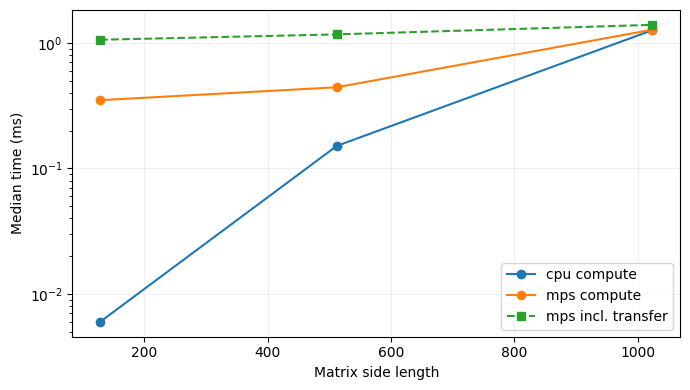

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
for dev in sorted({r["device"] for r in records}):
    rows = [r for r in records if r["device"]==dev]
    ax.plot([r["n"] for r in rows], [r["compute_ms"] for r in rows], "o-", label=dev+" compute")
    if dev != "cpu":
        ax.plot([r["n"] for r in rows], [r["transfer_ms"] for r in rows], "s--", label=dev+" incl. transfer")
ax.set(xlabel="Matrix side length", ylabel="Median time (ms)", yscale="log")
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

計測値はこの機械・電源状態・バックエンド・ライブラリ版に依存します。小さな行列では転送や起動の費用が目立ち、GPUが常に速いとは限りません。GPUなしならCPUの線だけを見ます。

## 条件を変える実験

512×512のCPU行列積でスレッド数1・2を比較します。他のソフトウェアの負荷も結果に影響します。

In [4]:
try:
    for threads in [1,2]:
        torch.set_num_threads(threads)
        a = torch.randn(512,512)
        b = torch.randn(512,512)
        print("CPU threads", threads, "median ms", round(median_ms(lambda: a @ b, torch.device("cpu")),4))
finally:
    torch.set_num_threads(2)

CPU threads 1 median ms 0.1493
CPU threads 2 median ms 0.1468


同じ計算でも条件で時間は変わります。元の測定をやり直す場合はスレッド数やサイズ、回数の条件をそろえてください。

## まとめ

演算そのものとデータ転送、非同期処理の同期を区別して時間を比較しました。保存済み出力で測定できたデバイスを確認してください。利用できないGPUの性能は推測しません。

## 参考資料

- [PyTorch CUDA synchronize](https://docs.pytorch.org/docs/stable/generated/torch.cuda.synchronize.html)
- [PyTorch MPS synchronize](https://docs.pytorch.org/docs/stable/generated/torch.mps.synchronize.html)
- [PyTorch benchmarkの解説](https://docs.pytorch.org/tutorials/recipes/recipes/benchmark.html)